# Anleitung für das Training

Hier wird gezeigt wie das Retraining des Modells wie es in der Main Applikation funktioniert. \
Hier werden die Daten jedoch manuell geladen sonst wird alles gleich exekutiert.

# 1. Laden der Librarys welche man braucht um dieses Notebook durchlaufen zu lassen

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import app

%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

# 2. Laden der Daten (Manuell)

In der Applikation wie sie im Presswerk integriert ist werden die Daten jedoch automatisch geladen

In [2]:
#manuelles Laden
df = pd.read_csv("Prod_data/data.csv", sep=',')

In [3]:
#Wenn man ein beliebiges Dataset laden will (nicht unbedingt Motorströme) dann kann man auch nur das Dataframe laden.
df = df[['time', 'Spannung_L1_L2_Hauptantrieb', 'Spannung_L2_L3_Hauptantrieb', 'Spannung_L3_L1_Hauptantrieb','Strom_L1_Hauptantrieb','Strom_L2_Hauptantrieb', 'Strom_L3_Hauptantrieb']]

# 3. Trainingsinstanz erzeugen 

Hier wird diese Instanz "session" genannt, aber man könnte sie beliebig benennen

In [4]:
session = app.Training(df)

Raw Data imported


# 4. Vorverarbeiten der Daten 

Hier werden die features generiert/aggregiert/angereichert welche man später benutzt um sein Modell zu trainieren

In [5]:
test = session.preprocessing(feature_selection=False)

Spannung_L1_L2_Hauptantrieb
Spannung_L2_L3_Hauptantrieb
Spannung_L3_L1_Hauptantrieb
Strom_L1_Hauptantrieb
Strom_L2_Hauptantrieb
Strom_L3_Hauptantrieb


# 5. Trainieren des Modells

Hier wird dann das Anomalieerkennungs Modell trainiert und in einen Ordner welcher unter "saving_path" benannt ist gespeichert

False
Training Data: 2022-10-14 until 2023-03-01
Validation Data: 2023-03-01 until 2023-05-15
Validation Data: 2023-05-15 until latest


2023-10-09 12:54:55.026329: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Epoch 1/100
3093/3093 [==============================] - 30s 8ms/step - loss: 0.1274 - val_loss: 0.0608
Epoch 2/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0440 - val_loss: 0.0579
Epoch 3/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0424 - val_loss: 0.0553
Epoch 4/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0361 - val_loss: 0.0442
Epoch 5/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0318 - val_loss: 0.0433
Epoch 6/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0308 - val_loss: 0.0444
Epoch 7/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0302 - val_loss: 0.0442
Epoch 8/100
3093/3093 [==============================] - 23s 7ms/step - loss: 0.0298 - val_loss: 0.0425
Epoch 9/100
3093/3093 [==============================] - 23s 8ms/step - loss: 0.0289 - val_loss: 0.0405
Epoch 10/100
3093/3093 [==============================] - 24s 8m

INFO:tensorflow:Assets written to: models/model_LSTM_AE_embedding_8_epochs_100_sequence_length_3_unsupervised_20231009feature_selection_False/assets


time: 2345.876383781433


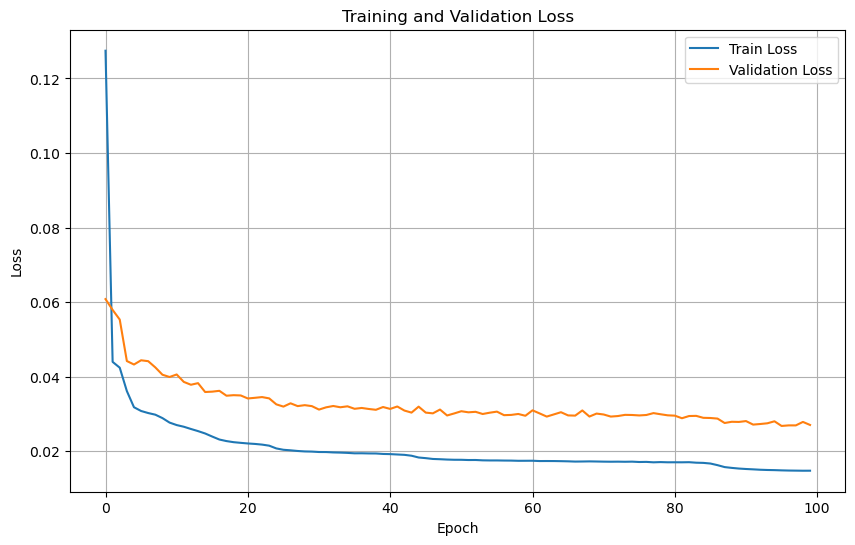

In [6]:
session.trainUnsupervised(epochs= 100, saving_path='models/', sequence_length = 3)